# Which way of carrying an update into the decomposition keeps the behaviour and stays faithful?

*E16, 2026-10-21. Plan: `reports/2026-10-21_plan_split-comparison.md`. Record: `reports/2026-10-21_analysis_split-comparison.md`.*

## The answer

Of the five operations, only component training kept the behaviour and a faithful decomposition while leaving Δ untouched. It did so at every step we checked, beside both the fine-tune and the LoRA. The least-squares split keeps the whole update, but on the fine-tune the adversary does up to seven times its usual damage. The adjoint and rescaling splits stay faithful and lose most or all of the behaviour. Component training is trained in place of the update, so it is an analogue, not the same update.

**The filed predictions are not scored.** The run had to reproduce the previous run, E14, before anything else was read. Twenty-two of the twenty-four checked readings did. The two misses are both the fine-tune at step 10. Its least-squares state read 6.96 where E14 read 5.24. Its do-nothing state read 2.52 where E14 read 2.29. As filed, this failed gate leaves three predictions unscored. Their conditions appear below as readings, not verdicts. The positive control also missed at one point of six; see Surprises.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

R = Path('../experiments/split_comparison/results')
F = Path('../experiments/split_comparison/figures')
out = json.loads((R / 'split_comparison.json').read_text())
rows, W0, score = out['rows'], out['W0'], out['score']
f = W0['pgd_floor']
print(f'{len(rows)} states; W0 adversarial floor f = {f:.3f}, band {1 - 3 * f:.2f} to {1 + 3 * f:.2f}')

30 states; W0 adversarial floor f = 0.075, band 0.78 to 1.22


## What we were trying to test

The model is the released VPD decomposition of a 67M-parameter language model. Each of its 24 decomposed matrices is $W = U V^\top + \Delta$. The columns of $V$ are the subcomponents' read vectors $v_c$. The columns of $U$ are their write vectors $u_c$. Δ is the residual the subcomponents do not explain. Γ decides how strongly each subcomponent is switched on for each input, and stays frozen throughout.

The task: after an emoticon, predict one target token. Two updates teach it, a full fine-tune and a rank-8 LoRA, both on all 24 matrices. Each is taken at steps 10, 100 and 1000. Write $\delta W$ for one update's weight change.

**Four operations consume a finished update**, so each applies to the fine-tune and to the LoRA alike.

- **Do-nothing** puts the update in the residual: $W' = U V^\top + (\Delta + \delta W)$. It is the reference.
- **Least-squares split**: the least-norm $(dU, dV)$ with $dU V^\top + U dV^\top \approx \delta W$, remainder to Δ. The model is exactly the updated model.
- **Adjoint split**: $dU = \delta W V$ and $dV = \delta W^\top U$, scaled per matrix to best match $\delta W$ on real inputs. Δ stays fixed, so this is a different model.
- **Rescaling split**: scale each $u_c$ by $1 + \alpha_c$, where $\sum_c \alpha_c u_c v_c^\top$ best fits $\delta W$. Directions and Δ stay fixed. This run is its first test as a model.

**The fifth operation consumes no update.** Component training trains $U$ and $V$ on the task loss itself, with Γ and Δ frozen, in place of fine-tuning. It has no exact match for either update, only an analogue. Beside the fine-tune: free component training of every alive subcomponent at learning rate 1e-5. Beside the LoRA: rank-8 component training, whose changes are rank 8 per matrix, at learning rate 1e-4. Both run 1000 steps and are read at the same three steps.

For each of the 30 states we read four things.

- **Faithfulness.** VPD's checks on 256 Pile rows, as ratios to the unchanged model W₀; 1 means as faithful as W₀. The adversarial check matters most: an attacker picks the most damaging masks. W₀'s own adversarial reading spreads by $f$ across three attacker seeds, so $1 \pm 3f$ is the noise band.
- **Overlap.** Δ's share of $\|\delta W\|^2$: 0 when Δ is untouched, 1 for do-nothing. The reproduced share $R$: the fraction of the update's input-weighted energy the state carries. The outside share: the part of a weight change outside both what the subcomponents read and what they write, against a random change of the same size.
- **Behaviour kept.** The target's probability on held-out trigger windows: 0.012 at W₀, at least 0.999 for both updates.
- **Where the gain goes.** The gain is the rise in the target's log-probability, in nats. The direct share $d$ is the part the moved vectors carry under W₀'s masks. The re-switching share $r$ is the part Γ carries by switching different subcomponents on.

## What we expected, and why

- **The gate.** Same updates, same harness: do-nothing, least-squares and adjoint adversarial ratios within 0.22 of E14's.
- **The rescaling state stays at W₀.** E14 found rescaling reproduces only 2 to 7 percent of an update's energy. So: faithful, under a tenth of the update, the target's probability below 0.05.
- **Component training keeps both.** Earlier short runs learned the task within a few steps near the floor. So: probability at least 0.9 from step 100, adversarial ratio under 1.5 at steps 10 and 100.
- **The control.** Component training's first-order change $dU V^\top + U dV^\top$ is inside the subcomponents by construction. So its outside-both share should stay below 0.01.
- **No direct route.** Wherever the gain exceeds 1 nat, the moved vectors carry at most 0.15 of it, as in the last two runs.

## What we observed

### 1. Which operation keeps the behaviour, stays faithful and leaves Δ alone?

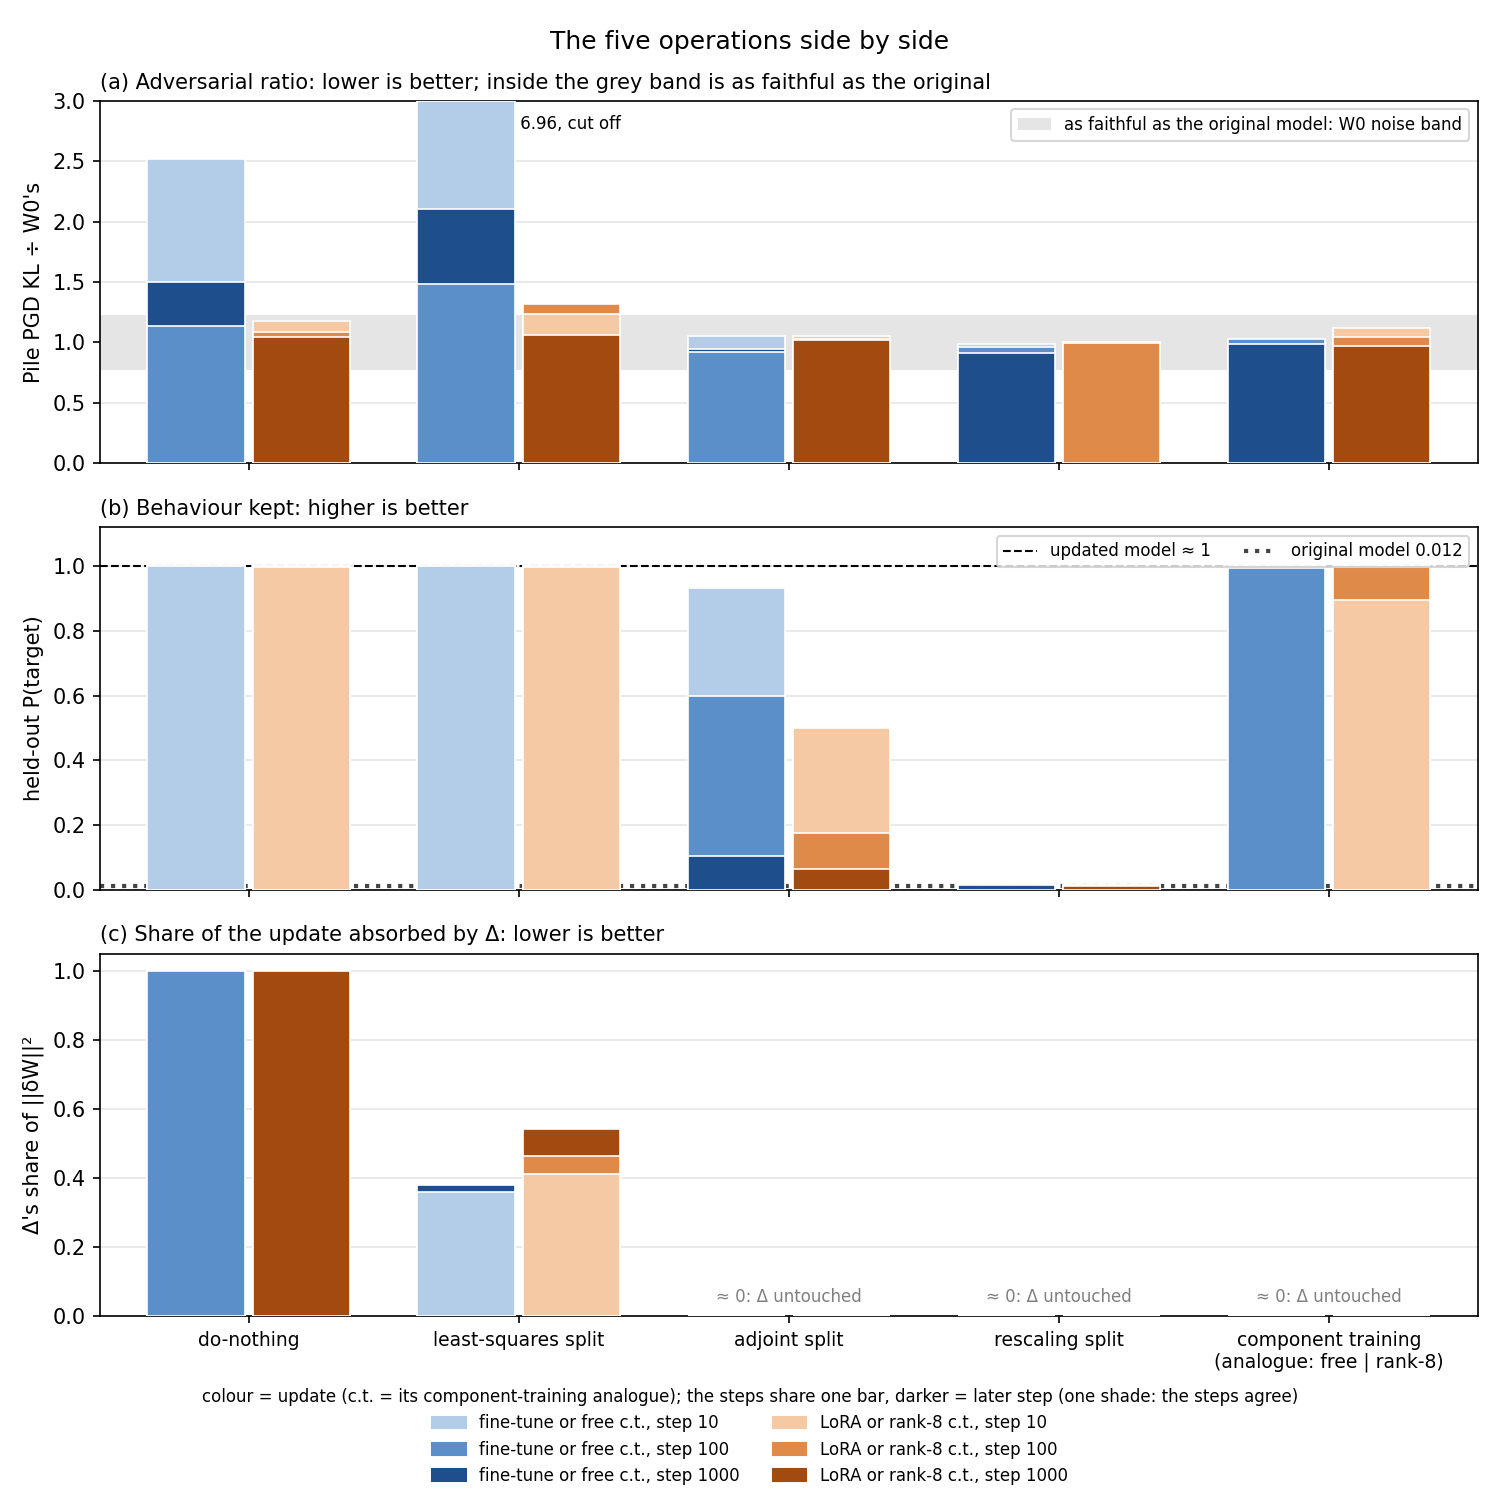

In [2]:
display(Image(F / 'bars.png', width=900))

**Reading it.** Only component training does all three. Its bars sit in the grey band at the top, reach the updated model's level in the middle and are zero at the bottom. Do-nothing and the least-squares split keep the behaviour but put all or part of the update in Δ. For the fine-tune they also leave the band. The adjoint and rescaling splits stay faithful and leave Δ alone, but lose most or all of the behaviour. The adjoint state's behaviour falls along training as the share of the update it reproduces falls. That share is at most 58 percent of the fine-tune and at most 23 percent of the LoRA. The rescaling split reproduces at most 7 percent, and its behaviour stays at the original model's level. Do-nothing and the least-squares split reproduce all of the update, the least-squares split partly through Δ. Component training's bars are analogues, not the same update: it is trained in place of fine-tuning.

### 2. How faithful does each state stay under the adversary, along training?

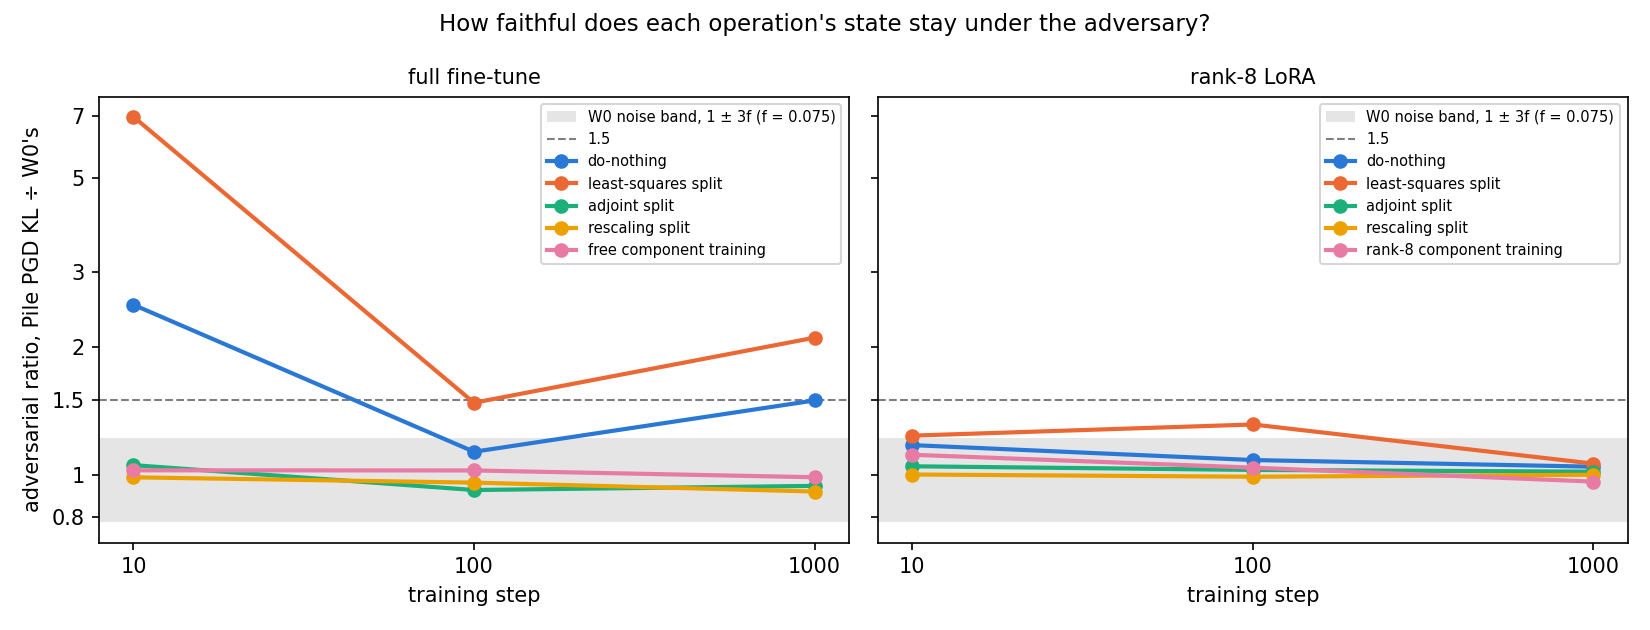

In [3]:
display(Image(F / 'pgd.png', width=1000))

**Reading it.** The adjoint split, the rescaling split and component training stayed faithful at every step, beside both updates. For the fine-tune, do-nothing and the least-squares split did not stay faithful. Both leave the band at steps 10 and 1000, the least-squares state worst at step 10. For the LoRA they stay close, and only the least-squares state sits just above the band at steps 10 and 100. The two step-10 fine-tune readings are the ones that failed to reproduce the previous run, so their exact height is uncertain.

### 3. How much of each weight change can the subcomponents not express?

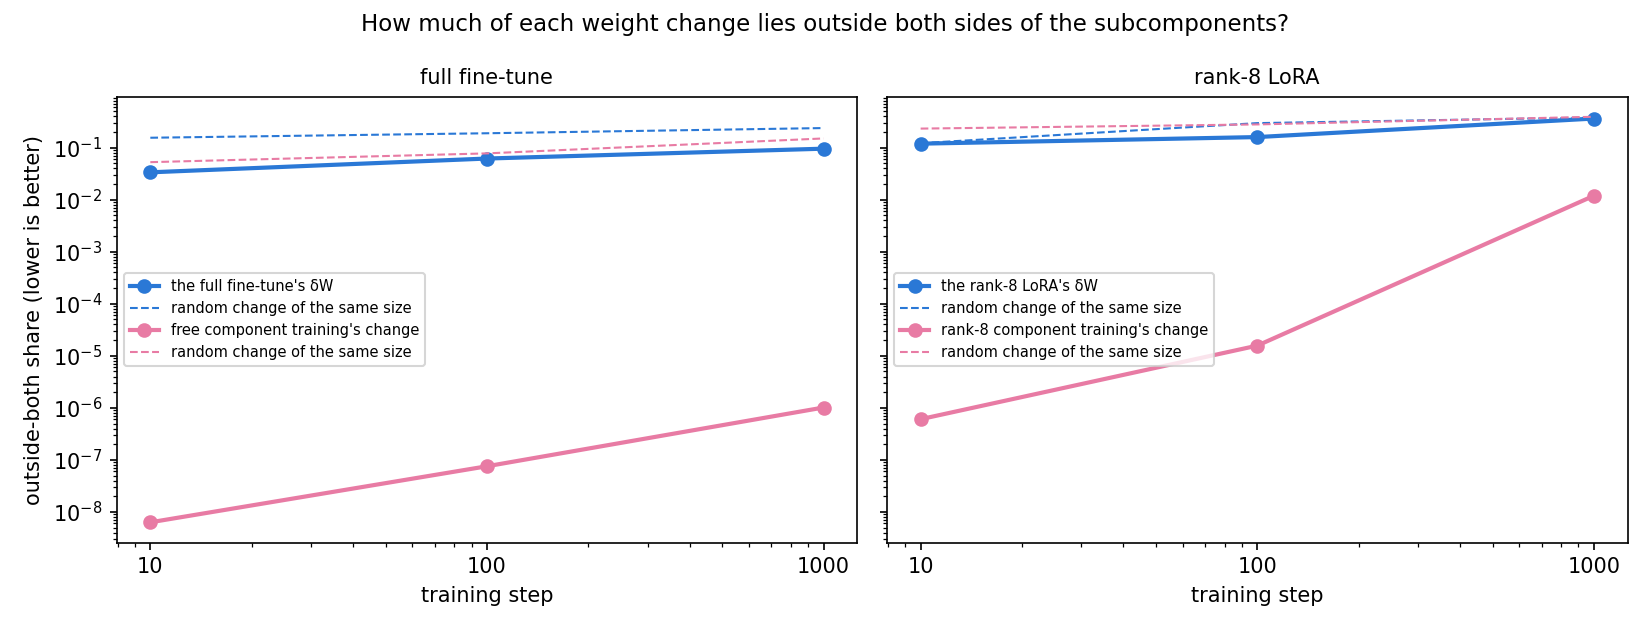

In [4]:
display(Image(F / 'outside.png', width=1000))

**Reading it.** Lower is better here, and the fine-tune looks better than the LoRA. The outside-both share is the part of a weight change that no first-order change of the subcomponents can produce on the data. So less outside means the subcomponents can express more of the update. Solid lines are the measured change and dashed lines a random change of the same size. The fine-tune sits well below random at every step, between a fifth and two fifths of it. The LoRA sits between half of random and random itself, so the subcomponents express it little better than a random change. Component training, the positive control, sits near zero by construction; its one exception is discussed under Surprises.

### 4. Does the gain on the target come from the moved subcomponents or from Γ switching others on?

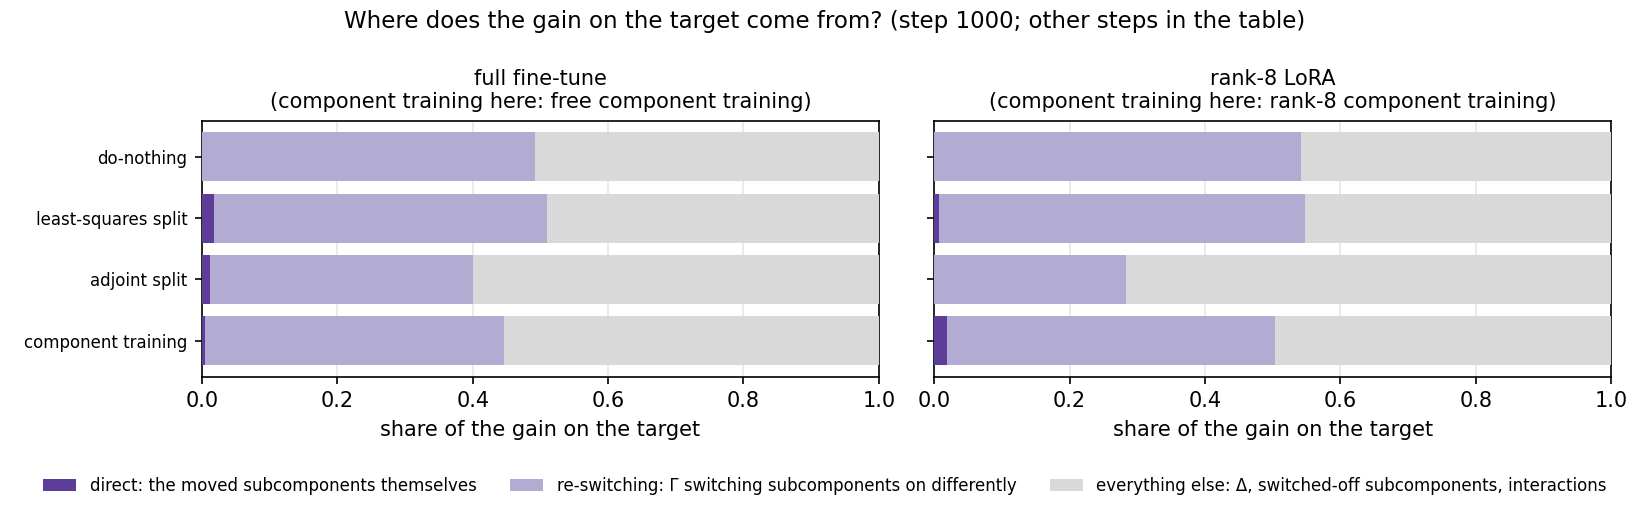

In [5]:
display(Image(F / 'routes.png', width=1000))

**Reading it.** Whichever operation, the gain goes through Γ switching subcomponents on, not through the moved subcomponents. This figure reads the mechanism, not a pass or a fail: neither route is the good one. The bars show step 1000; the earlier steps look alike and are in the table. Each bar splits the gain, the rise in the target's log-probability, into three parts. The direct share, dark, is what the moved subcomponents carry by themselves, as when an update strengthens subcomponents that already exist. The re-switching share, light, is what Γ carries by switching existing subcomponents on differently. The grey rest comes from Δ, from subcomponents that are switched off, and from interactions between the two. The direct share stays below a tenth everywhere, while re-switching carries between about a third and two thirds across all steps. Do-nothing moves no subcomponent, so its direct share is zero by construction. The rescaling split is left out. It raises the target's log-probability by under 0.4, against at least 1.7 for every other state, too little to divide.

## What we learned

`GOALS.md`'s weak version asks for a state about as faithful as W₀, with Δ not absorbing the update. On the emoticon task, component training meets it to step 1000, in a free and a rank-8 variant. None of the four splits of a finished update meets it. The adjoint and rescaling splits are faithful but carry only part of the update. The least-squares split carries all of it through Δ and, for the fine-tune, fails the adversary. So the behaviour can be reached inside the decomposition, but a finished update cannot be carried into it. Resizing the existing subcomponents carries none of the behaviour.

## How compelling is the evidence

One task, and one seed for each update and each component-training variant, on one H100. The noise band comes from three attacker seeds on W₀. The Pile checks are blind to the behaviour; the target's probability is blind to other tokens. The split states' off-target damage and every state's sparsity loss were not measured. The step-10 fine-tune state is the least stable reading in the project: its least-squares state has read between 5.2 and 7.3 across five runs. Component training is compared with an analogue, not the same update.

## Surprises

No filed prediction reversed. Two filed checks missed.

**The gate.** The step-10 fine-tune's least-squares state read 6.96 against E14's 5.24, outside a tolerance of 0.22. Its do-nothing state missed by 0.002 beyond the same tolerance. The other 22 readings reproduce. As facts, not a cause: this run used an H100 and E14 an RTX A5000. W₀'s adversarial spread was 0.075 here and 0.122 there. The Γ refit run, E15, also on an H100, read this same state at 6.96. Why the readings differ is not established.

**The control.** Rank-8 component training's outside-both share at step 1000 read 0.012, above the filed 0.01. The other five points read at most 2e-5. The expected source is the second-order product $dU\,dV^\top$. It was not measured, so the cause is not established.

## What next

- **Find why the step-10 fine-tune reading moves.** Read one saved state on an RTX A5000 and an H100. If it follows the card, step-10 comparisons need a same-card reference.
- **Close the control.** Compute $dU\,dV^\top$ of rank-8 component training at step 1000. If it accounts for the 0.012, the control holds to second order; if not, look for a bug.
- **Component training where the model lacks the association.** On one key-to-value task, component training once read 2.8 under the adversary. A failure there would tie this success to a behaviour the model nearly has. Through `/design` first.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| G1 | this run reproduces E14 | do-nothing, least-squares, adjoint adversarial ratios within max(0.15, 3f) = 0.224 of E14's; adjoint P(target) within 0.05; both updates, three steps | 22 of 24 within; ft step 10 least-squares 6.96 vs 5.24, do-nothing 2.52 vs 2.29 | **fail** |
| G2 | the least-squares state is the updated model | harness check per update and step | all six hold | pass |
| P1 | the rescaling state stays at W₀ | ratio ≤ 1 + 3f, P(target) < 0.05, R ≤ 0.1, every step, both updates | ratio 0.92–1.00, P 0.012–0.016, R 0.003–0.071: all 18 conditions met | unscored (G1 failed) |
| P2 | component training keeps both | P(target) ≥ 0.9 at steps 100, 1000; ratio < 1.5 at steps 10, 100; both variants | P 0.994–0.9995, ratio 1.03–1.12: all 8 conditions met | unscored (G1 failed) |
| C1 | component training's change lies inside | outside-both block ≤ 0.01, every step, both variants | free ≤ 1e-6; rank-8 6e-7, 2e-5, 0.0119 | **fail** at rank-8 step 1000 |
| P3 | no direct route | d ≤ 0.15 for every state with gain > 1 nat | d ≤ 0.080: all 24 conditions met | unscored (G1 failed) |

Step 1000's component-training ratio, a first reading with no threshold: 0.99 free, 0.97 rank-8.

## The full table

Every state, for reference. Ratios are to W₀; the noise band is 0.78 to 1.22.

In [6]:
OPS = {'nothing': 'do-nothing', 'least_squares': 'least-squares', 'adjoint': 'adjoint',
       'rescaling': 'rescaling', 'component_training': 'component training'}
PAIR = {'ft': 'fine-tune', 'lora24': 'LoRA'}
COLS = [('pgd', 'adversarial'), ('stochastic', 'stochastic'), ('ci_masked', 'CI-masked'), ('unmasked', 'unmasked'),
        ('delta_share', 'Δ share'), ('R', 'R'), ('p_target', 'P(target)'), ('gain', 'gain, nats'), ('d', 'd'), ('r', 'r')]
head = '| update | step | operation | ' + ' | '.join(n for _, n in COLS) + ' |'
lines = [head, '|' + '---|' * (3 + len(COLS))]
for r in rows:
    vals = ' | '.join(f'{r[k]:.3g}' for k, _ in COLS)
    lines.append(f"| {PAIR[r['pair']]} | {r['step']} | {OPS[r['op']]} | {vals} |")
display(Markdown('\n'.join(lines)))

| update | step | operation | adversarial | stochastic | CI-masked | unmasked | Δ share | R | P(target) | gain, nats | d | r |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| fine-tune | 10 | do-nothing | 2.52 | 1 | 0.999 | 2.89 | 1 | 1 | 0.999 | 13.5 | 0 | 0.597 |
| fine-tune | 10 | least-squares | 6.96 | 1 | 0.997 | 1.21 | 0.359 | 1 | 0.999 | 13.5 | 0.0527 | 0.597 |
| fine-tune | 10 | adjoint | 1.06 | 0.993 | 0.99 | 0.979 | 1.56e-06 | 0.577 | 0.933 | 8.57 | 0.0801 | 0.668 |
| fine-tune | 10 | rescaling | 0.989 | 1 | 1 | 1 | 4.36e-09 | 0.0199 | 0.0163 | 0.351 | 0.171 | 0.244 |
| fine-tune | 10 | component training | 1.03 | 0.998 | 1 | 1.01 | 1.96e-08 | 1 | 1 | 15 | 0.0255 | 0.529 |
| fine-tune | 100 | do-nothing | 1.14 | 0.956 | 0.99 | 2.81 | 1 | 1 | 0.999 | 14.1 | 0 | 0.526 |
| fine-tune | 100 | least-squares | 1.48 | 0.957 | 0.989 | 1.06 | 0.38 | 1 | 0.999 | 14.1 | 0.0449 | 0.526 |
| fine-tune | 100 | adjoint | 0.924 | 0.962 | 0.994 | 0.904 | 2.62e-06 | 0.422 | 0.6 | 5.52 | 0.0634 | 0.5 |
| fine-tune | 100 | rescaling | 0.961 | 0.994 | 0.997 | 0.987 | 3.33e-09 | 0.0271 | 0.0133 | 0.161 | 0.113 | 0.224 |
| fine-tune | 100 | component training | 1.03 | 0.994 | 0.999 | 0.98 | 6.97e-09 | 1 | 0.994 | 12.2 | 0.0229 | 0.496 |
| fine-tune | 1000 | do-nothing | 1.5 | 0.916 | 0.988 | 5.53 | 1 | 1 | 1 | 17.9 | 0 | 0.491 |
| fine-tune | 1000 | least-squares | 2.11 | 0.921 | 0.992 | 1.18 | 0.379 | 1 | 1 | 17.9 | 0.0183 | 0.491 |
| fine-tune | 1000 | adjoint | 0.945 | 0.944 | 0.997 | 0.848 | 7.72e-06 | 0.314 | 0.104 | 2.36 | 0.0111 | 0.39 |
| fine-tune | 1000 | rescaling | 0.916 | 0.986 | 1 | 0.967 | 1e-09 | 0.0706 | 0.0128 | 0.128 | 0.0547 | 0.172 |
| fine-tune | 1000 | component training | 0.99 | 0.985 | 0.995 | 0.954 | 1.84e-09 | 1 | 0.997 | 16.8 | 0.00505 | 0.441 |
| LoRA | 10 | do-nothing | 1.18 | 1.01 | 1.01 | 2 | 1 | 1 | 0.999 | 14.5 | 0 | 0.582 |
| LoRA | 10 | least-squares | 1.24 | 1.01 | 1.01 | 1.35 | 0.41 | 1 | 0.999 | 14.5 | 0.0166 | 0.582 |
| LoRA | 10 | adjoint | 1.05 | 1 | 1 | 1.01 | 6.4e-06 | 0.225 | 0.499 | 4.91 | 0.0109 | 0.571 |
| LoRA | 10 | rescaling | 1 | 1 | 1 | 0.994 | 9.7e-09 | 0.0128 | 0.0131 | 0.121 | 0.07 | 0.362 |
| LoRA | 10 | component training | 1.12 | 1.02 | 1.02 | 1.02 | 1.18e-08 | 1 | 0.895 | 8.15 | 0.0512 | 0.565 |
| LoRA | 100 | do-nothing | 1.09 | 0.996 | 0.999 | 1.99 | 1 | 1 | 1 | 14.3 | 0 | 0.559 |
| LoRA | 100 | least-squares | 1.32 | 0.996 | 1 | 1.27 | 0.463 | 1 | 1 | 14.3 | 0.0133 | 0.559 |
| LoRA | 100 | adjoint | 1.03 | 0.998 | 1 | 0.979 | 5.71e-06 | 0.116 | 0.176 | 3.06 | 0.000331 | 0.392 |
| LoRA | 100 | rescaling | 0.992 | 0.998 | 0.998 | 0.998 | 1.44e-08 | 0.00531 | 0.0129 | 0.111 | -0.00871 | 0.218 |
| LoRA | 100 | component training | 1.04 | 1 | 1 | 1 | 3.3e-09 | 1 | 0.996 | 11.5 | 0.0437 | 0.564 |
| LoRA | 1000 | do-nothing | 1.05 | 1 | 1 | 1.5 | 1 | 1 | 1 | 15.3 | 0 | 0.542 |
| LoRA | 1000 | least-squares | 1.07 | 1 | 1 | 1.21 | 0.542 | 1 | 1 | 15.3 | 0.00639 | 0.542 |
| LoRA | 1000 | adjoint | 1.02 | 0.997 | 0.998 | 0.986 | 0.000265 | 0.107 | 0.0629 | 1.7 | 0.00031 | 0.283 |
| LoRA | 1000 | rescaling | 1 | 0.999 | 0.999 | 0.995 | 1.86e-08 | 0.00269 | 0.0123 | 0.0634 | -0.0577 | 0.321 |
| LoRA | 1000 | component training | 0.967 | 1 | 1 | 0.997 | 9.33e-10 | 1 | 0.999 | 16.4 | 0.0187 | 0.484 |

## Not run

- A second seed for either update or either component-training variant.
- The off-target KL of the four split states; no code measures it.
- The sparsity loss of any state.
- The product $dU\,dV^\top$ of component training, which the control's miss needs.
- The step-10 fine-tune state on E14's card, which the gate's miss needs.
- The key-to-value tasks.

## Provenance

Results `experiments/split_comparison/results/split_comparison.json`, sha256 3db95e00…d155d8. Log `results/large/full.log`. Figures from `experiments/split_comparison/plot.py`. RunPod H100 80GB on 2026-10-21; scored run 35 minutes; $3.68 in all. Predictions `results/predictions.json`, filed before the run.